# Imports

In [1]:
import os
import sys
import pandas as pd
sys.path.append('../..')
import plotly.express as px
from plotly.graph_objs import Figure
import seaborn as sns
from src.shared.env import env
from functools import cache
from definitions import ROOT_DIR

In [2]:
px.defaults.template = "seaborn"

# Utils

In [3]:
FIGURES_DIR = os.path.join(ROOT_DIR, 'assets', 'health_care')
os.makedirs(FIGURES_DIR, exist_ok=True)

In [4]:
def save_fig(fig : Figure, filename : str) -> None:
    fig.write_image(os.path.join(FIGURES_DIR, filename))

In [5]:
def style_paper_line(
    fig,
    *,
    width=950,
    height=600,
    font_family="Arial",
    font_size=14,
):
    fig.update_traces(
        line=dict(width=2),
        marker=dict(size=7),
        marker_symbol="diamond"
    )

    fig.update_layout(
        width=width,
        height=height,
        font=dict(
            family=font_family,
            size=font_size,
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin=dict(
            l=80,
            r=30,
            t=30,
            b=70,
        ),
    )

    fig.update_xaxes(
        showgrid=True,
        gridcolor="lightgray",
        gridwidth=0.5,
        zeroline=False,
        ticks="outside",
        showline=True,
        linewidth=1,
        linecolor="black",
    )

    fig.update_yaxes(
        showgrid=True,
        gridcolor="lightgray",
        gridwidth=0.5,
        zeroline=False,
        ticks="outside",
        showline=True,
        linewidth=1,
        linecolor="black",
    )

    

    return fig

In [6]:
def style_paper_histogram(
    fig,
    *,
    width=950,
    height=600,
    font_family="Arial",
    font_size=14,
):
    fig.update_layout(
        width=width,
        height=height,
        font=dict(
            family=font_family,
            size=font_size,
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin=dict(
            l=80,
            r=30,
            t=30,
            b=70,
        ),
    )

    fig.update_xaxes(
        showgrid=False,
        zeroline=False,
        ticks="outside",
        showline=True,
        linewidth=1,
        linecolor="black",
    )

    fig.update_yaxes(
        showgrid=True,
        gridcolor="lightgray",
        gridwidth=0.5,
        zeroline=False,
        ticks="outside",
        showline=True,
        linewidth=1,
        linecolor="black",
    )

    return fig

In [7]:
def style_paper_bar(
    fig,
    *,
    width=950,
    height=600,
    font_family="Arial",
    font_size=14,
):
    fig.update_layout(
        width=width,
        height=height,
        font=dict(
            family=font_family,
            size=font_size,
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin=dict(
            l=80,
            r=30,
            t=30,
            b=70,
        ),
    )

    fig.update_xaxes(
        showgrid=True,
        gridcolor="lightgray",
        gridwidth=0.5,
        zeroline=False,
        ticks="outside",
        showline=True,
        linewidth=1,
        linecolor="black",
    )

    fig.update_yaxes(
        showgrid=False,
        zeroline=False,
        ticks="outside",
        showline=False,
    )

    return fig

In [8]:
class Queries:

    Articles_By_DSI = """
        MATCH (a:Article)-[r:BELONGSTO]->(d:SubDomain) 
        WITH d.name AS DSI, count(DISTINCT a) as Number_Of_Articles 
        RETURN DSI, Number_Of_Articles;
    """

    Articles_By_Domain = """
        MATCH (a:Article)-[:BELONGSTO]->(:SubDomain)-[:ISSUBDOMAINOF]->(d:Domain)
        WITH d.name AS Domain, count(DISTINCT a) as Number_Of_Articles 
        RETURN Domain, Number_Of_Articles;
    """

    Articles_By_Lab = """
        MATCH (:SubDomain)<-[:BELONGSTO]-(a:Article)-[:BELONGSTO]->(l:Lab)
        WITH l.name AS Lab, count(DISTINCT a) as Number_Of_Articles 
        RETURN Lab, Number_Of_Articles;
    """

    Expertises_By_DSI = """
        MATCH (a:Expertise)-[r:BELONGSTO]->(d:SubDomain ) 
        WITH d.name AS DSI, count(DISTINCT a) as Number_Of_Expertises 
        RETURN DSI, Number_Of_Expertises;
    """

    Expertises_By_Domain = """
        MATCH (a:Expertise)-[:BELONGSTO]->(:SubDomain )-[:ISSUBDOMAINOF]->(d:Domain)
        WITH d.name AS Domain, count(DISTINCT a) as Number_Of_Expertises 
        RETURN Domain, Number_Of_Expertises;
    """

    Expertises_By_Lab = """
        MATCH (:SubDomain)<-[:BELONGSTO]-(a:Expertise)-[r:BELONGSTO]->(d:Lab) 
        WITH d.name AS Lab, count(DISTINCT a) as Number_Of_Expertises 
        RETURN Lab, Number_Of_Expertises;
    """

    Articles_Expertises_By_Lab = """
        MATCH (:SubDomain)<-[:BELONGSTO]-(e:Expertise)-[:BELONGSTO]->(l:Lab)<-[:BELONGSTO]-(a:Article)-[:BELONGSTO]->(:SubDomain)
        WITH l.name as Lab, count(DISTINCT a) as Number_Of_Articles, count(DISTINCT e) as Number_Of_Expertises 
        RETURN Lab, Number_Of_Articles, Number_Of_Expertises;
    """

    Articles_Expertises_By_Domain = """
        MATCH (e:Expertise)-[:BELONGSTO]->(d:SubDomain)<-[:BELONGSTO]-(a:Article) 
        WITH d.name as DSI, count(DISTINCT a) as Number_Of_Articles, count(DISTINCT e) as Number_Of_Expertises 
        RETURN DSI, Number_Of_Articles, Number_Of_Expertises;
    """

    Expertise_By_Lab_DSI = """
        MATCH (l:Lab)<-[:BELONGSTO]-(e:Expertise)-[:BELONGSTO]->(d:SubDomain) 
        WITH l.name AS Lab, d.name as Domain, count(DISTINCT e) as Number_Of_Expertises 
        RETURN Lab, Domain, Number_Of_Expertises;
    """

    Articles_By_Expertises = """
        MATCH (a:Article)<-[:APPEARIN]-(e:Entity)-[:BELONGSTO]->(ex:Expertise)-[:BELONGSTO]->(:SubDomain) 
        WITH ex.llm_label as name , count(DISTINCT a) as Number_of_Articles 
        RETURN name, Number_of_Articles;
    """

In [9]:
class Queries:

    Articles_By_DSI = """
        MATCH (a:Article)-[r:BELONGSTO]->(d:SubDomain { is_valid : True }) 
        WITH d.name AS DSI, count(DISTINCT a) as Number_Of_Articles 
        RETURN DSI, Number_Of_Articles;
    """

    Articles_By_Domain = """
        MATCH (a:Article)-[:BELONGSTO]->(:SubDomain { is_valid : True })-[:ISSUBDOMAINOF]->(d:Domain)
        WITH d.name AS Domain, count(DISTINCT a) as Number_Of_Articles 
        RETURN Domain, Number_Of_Articles;
    """

    Articles_By_Lab = """
        MATCH (:SubDomain { is_valid : True })<-[:BELONGSTO]-(a:Article)-[:BELONGSTO]->(l:Lab)
        WITH l.name AS Lab, count(DISTINCT a) as Number_Of_Articles 
        RETURN Lab, Number_Of_Articles;
    """

    Expertises_By_DSI = """
        MATCH (a:Expertise)-[r:BELONGSTO]->(d:SubDomain { is_valid : True }) 
        WITH d.name AS DSI, count(DISTINCT a) as Number_Of_Expertises 
        RETURN DSI, Number_Of_Expertises;
    """

    Expertises_By_Domain = """
        MATCH (a:Expertise)-[:BELONGSTO]->(:SubDomain { is_valid : True })-[:ISSUBDOMAINOF]->(d:Domain)
        WITH d.name AS Domain, count(DISTINCT a) as Number_Of_Expertises 
        RETURN Domain, Number_Of_Expertises;
    """

    Expertises_By_Lab = """
        MATCH (:SubDomain { is_valid : True })<-[:BELONGSTO]-(a:Expertise)-[r:BELONGSTO]->(d:Lab) 
        WITH d.name AS Lab, count(DISTINCT a) as Number_Of_Expertises 
        RETURN Lab, Number_Of_Expertises;
    """

    Articles_Expertises_By_Lab = """
        MATCH (:SubDomain { is_valid : True })<-[:BELONGSTO]-(e:Expertise)-[:BELONGSTO]->(l:Lab)<-[:BELONGSTO]-(a:Article)-[:BELONGSTO]->(:SubDomain { is_valid : True })
        WITH l.name as Lab, count(DISTINCT a) as Number_Of_Articles, count(DISTINCT e) as Number_Of_Expertises 
        RETURN Lab, Number_Of_Articles, Number_Of_Expertises;
    """

    Articles_Expertises_By_Domain = """
        MATCH (e:Expertise)-[:BELONGSTO]->(d:SubDomain { is_valid : True })<-[:BELONGSTO]-(a:Article) 
        WITH d.name as DSI, count(DISTINCT a) as Number_Of_Articles, count(DISTINCT e) as Number_Of_Expertises 
        RETURN DSI, Number_Of_Articles, Number_Of_Expertises;
    """

    Expertise_By_Lab_DSI = """
        MATCH (l:Lab)<-[:BELONGSTO]-(e:Expertise)-[:BELONGSTO]->(d:SubDomain { is_valid : True }) 
        WITH l.name AS Lab, d.name as Domain, count(DISTINCT e) as Number_Of_Expertises 
        RETURN Lab, Domain, Number_Of_Expertises;
    """

    Articles_By_Expertises = """
        MATCH (a:Article)<-[:APPEARIN]-(e:Entity)-[:BELONGSTO]->(ex:Expertise)-[:BELONGSTO]->(:SubDomain { is_valid : True }) 
        WITH ex.llm_label as name , count(DISTINCT a) as Number_of_Articles 
        RETURN name, Number_of_Articles;
    """

In [10]:
@cache
def entity_count(entity_type : str) -> int:

    with env.driver.session() as session:
        result = session.run(f"MATCH (n:{entity_type}) RETURN count(DISTINCT n) as count")
        return result.single().get('count')

In [11]:
@cache
def _run_query(query : str) -> pd.DataFrame:

    records = []

    with env.driver.session() as session:

        result = session.run(query)

        for record in result:
            records.append(record.data())

    df = pd.DataFrame(records)
    df.columns = [col.replace('_', ' ') for col in df.columns]

    return df

In [12]:
def run_query(query : str, copy : bool = False) -> pd.DataFrame:

    r = _run_query(query=query)

    if copy:
        r = r.copy()

    return r

In [13]:
run_query(Queries.Articles_Expertises_By_Domain).drop(columns="DSI").corr()

,Number Of Articles,Number Of Expertises
Number Of Articles,1.000000,0.926588
Number Of Expertises,0.926588,1.000000


In [14]:
run_query(Queries.Articles_Expertises_By_Lab).drop(columns="Lab").corr()

,Number Of Articles,Number Of Expertises
Number Of Articles,1.000000,0.881339
Number Of Expertises,0.881339,1.000000


# Plots

- Number Of Articles By Domain

In [15]:
DSI_map = {
    "Digital Engineering of Products and Processes" : "DE-P&P",
    "Industrial Digitalization" : "ID",
    "Industrial Organization Performance" : "IOP",
    "Monitoring and Analysis" : "M&A",
    "Change Management" : "CM",
    "Preparation for New Jobs in the Future Industry" : "P4NJ-FI",
    "Decarbonization of Energy" : "DE",
    "Composites and New Materials" : "C&NM",
    "Recycling / Reuse" : "R&R",
    "Robotics" : "Robotics",
    "Processes and Assembly" : "P&A",
    "User-Centered Design" : "UCD",
    "Reduction and Treatment of Effluents and Waste" : "R&TEW",
    "Eco-responsible Processes" : "ERP",
    "Eco-design" : "ED",
    "Decarbonization of Mobility" : "DM",
    "Augmentation of Human Capabilities in Manufacturing" : "AHC-M",
    "Additive Manufacturing" : "AM"
}

In [31]:
data = run_query(Queries.Articles_By_Domain)
data['text'] = data['Number Of Articles'].apply(lambda x : f"{x} ({(100 * x/entity_count("Article")):.3f}%)")

fig = px.bar(
    data_frame=data,
    x="Number Of Articles",
    y="Domain",
)

fig = style_paper_bar(fig)
save_fig(fig, 'articles_by_domain.pdf')

fig.show()

- Number Of Articles By SubDomain

In [29]:
data = run_query(Queries.Articles_By_DSI)
data['text'] = data['Number Of Articles'].apply(lambda x : f"{x} ({(100 * x/entity_count("Article")):.3f}%)")
# data['DSI'] = data['DSI'].map(DSI_map)

fig = px.bar(
    data_frame=data,
    x="Number Of Articles",
    y="DSI",
    text='text',
)

fig = style_paper_bar(fig)
save_fig(fig, 'articles_by_subdomain.pdf')

fig.show()

- Number of Articles By Lab

In [38]:
data.to_csv("./expertises_by_lab.csv", index=False)

In [26]:
data = run_query(Queries.Articles_By_Lab)
data['text'] = data['Number Of Articles'].apply(lambda x : f"{x} ({(100 * x/entity_count("Article")):.3f}%)")

fig = px.bar(
    data_frame=data,
    x="Number Of Articles",
    y="Lab",
    text='text',
)

fig = style_paper_bar(fig)
save_fig(fig, 'articles_by_lab.pdf')

fig.show()

- Number Of Expertises By SubDomain

In [33]:
data = run_query(Queries.Expertises_By_DSI)
data['text'] = data['Number Of Expertises'].apply(lambda x : f"{x} ({(100 * x/entity_count("Expertise")):.3f}%)")
# data['DSI'] = data['DSI'].map(DSI_map)

fig = px.bar(
    data_frame=data,
    x="Number Of Expertises",
    y="DSI",
    text='text',
)

fig = style_paper_bar(fig)
save_fig(fig, 'expertises_by_subdomain.pdf')

fig.show()

- Number Of Expertises By Domain

In [35]:
data = run_query(Queries.Expertises_By_Domain)
data['text'] = data['Number Of Expertises'].apply(lambda x : f"{x} ({(100 * x/entity_count("Expertise")):.3f}%)")

fig = px.bar(
    data_frame=data,
    x="Number Of Expertises",
    y="Domain",
    text='text',
)

fig = style_paper_bar(fig)
save_fig(fig, 'expertises_by_domain.pdf')

fig.show()

- Number of Expertises By Lab

In [37]:
data = run_query(Queries.Expertises_By_Lab)
data['text'] = data['Number Of Expertises'].apply(lambda x : f"{x} ({(100 * x/entity_count("Expertise")):.3f}%)")

fig = px.bar(
    data_frame=data,
    x="Number Of Expertises",
    y="Lab",
    text='text',
)

fig = style_paper_bar(fig)
save_fig(fig, 'expertises_by_lab.pdf')

fig.show()

In [13]:
data = run_query(Queries.Articles_Expertises_By_Lab).sort_values(by="Number Of Articles")
data['size'] = 50

fig = px.scatter(
    data_frame=data,
    x="Number Of Articles",
    y="Number Of Expertises",
    size='size'
    # text="Lab",
)

for i, (_, row) in enumerate(data.iterrows()):

    fig.add_annotation(
        x=row["Number Of Articles"],
        y=row["Number Of Expertises"],
        text=row["Lab"],
        showarrow=True,
        arrowhead=0,
        ax=0,
        ay=int(2 * (i%2) - 1) * (30 + 10 * ((i+1) // 4)),
        font=dict(size=10),
        bgcolor="white",
        bordercolor="black",
        borderwidth=0.5,
        borderpad=2,
    )

fig = style_paper_line(fig)
save_fig(fig, 'articles_expertises_corr_by_lab.pdf')

fig.show()

In [14]:
data = run_query(Queries.Articles_Expertises_By_Domain).sort_values(by="Number Of Articles")
# data['DSI'] = data['DSI'].map(DSI_map)

fig = px.scatter(
    data_frame=data,
    x="Number Of Articles",
    y="Number Of Expertises",
)

fig = style_paper_line(fig)

for i, (_, row) in enumerate(data.iterrows()):

    fig.add_annotation(
        x=row["Number Of Articles"],
        y=row["Number Of Expertises"],
        text=row["DSI"],
        showarrow=True,
        arrowhead=0,
        ax=0,
        ay=int(2 * (i%2) - 1) * (30 + 10 * ((i+1) // 4)),
        font=dict(size=10),
        bgcolor="white",
        bordercolor="black",
        borderwidth=0.5,
        borderpad=2,
    )

save_fig(fig, 'articles_expertises_corr_by_subdomain.pdf')

fig.show()

In [23]:
data = run_query(Queries.Articles_By_Expertises)

fig = px.histogram(
    data_frame=data,
    x='Number of Articles',
    # width=950,
    # height=600,
)

fig = style_paper_histogram(fig)
save_fig(fig, 'number_of_articles.pdf')

fig.show()

In [25]:
data = run_query(Queries.Expertise_By_Lab_DSI)
data = data.groupby(by="Lab").agg(list).reset_index()
index = data['Lab']
data = list(map(lambda x : dict(zip(x[0],x[1])), zip(data['Domain'], data['Number Of Expertises'])))
data = pd.DataFrame(index=index,data=data).fillna(0.0).transpose()
domains_counts = run_query(Queries.Expertises_By_DSI).set_index("DSI")['Number Of Expertises']
data = pd.DataFrame(
    index=data.index,
    columns=data.columns,
    data=data.to_numpy() / domains_counts.loc[data.index].to_numpy()[:,None]
)

KeyError: "['User-Centered Design', 'Digital Engineering of Products and Processes', 'Eco-design', 'Composites and New Materials', 'Monitoring and Analysis', 'Eco-responsible Processes', 'Additive Manufacturing', 'Processes and Assembly', 'Industrial Digitalization', 'Recycling / Reuse', 'Reduction and Treatment of Effluents and Waste', 'Decarbonization of Energy', 'Decarbonization of Mobility', 'Industrial Organization Performance', 'Preparation for New Jobs in the Future Industry', 'Augmentation of Human Capabilities in Manufacturing', 'Change Management'] not in index"

<Axes: xlabel='Lab'>

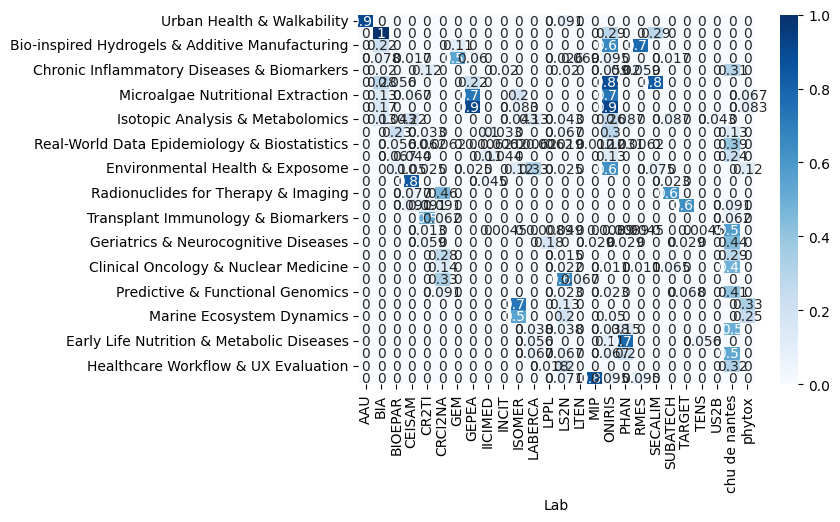

In [24]:
sns.heatmap(data, cmap='Blues', annot=True)

In [16]:
def get_interval(x : float, intervals : list[float]):

    if x <= intervals[0][0]:
        return f"{intervals[0][0]}"

    for a, b in intervals:

        if a < x <= b:

            if b - a > 1:
                return f"]{a:g}:{b:g}]"
            else:
                return f"{b}"
    
    return f"> {intervals[-1][-1]}"

In [17]:
def rank(x : str):

    if x.startswith('<'):
        return -1

    x = x.strip(' ><[]')

    if ':' in x:

        a, b = x.split(':')
        a, b = int(a), int(b)

        if b - a > 1:
            return a + 0.5
        else:
            return a

    return int(x)

In [52]:
get_interval(2, intervals)

']1:5]'

In [40]:
intervals

[(0, 1),
 (1, 5),
 (5, 10),
 (10, 20),
 (20, 30),
 (40, 50),
 (50, 75),
 (75, 100),
 (100, 150),
 (150, 200),
 (200, 250)]

In [38]:
df['%Triples > 0.25'].eq(1).sum()

np.int64(74)

In [18]:
df = run_query("""
MATCH (src:Entity)-[:HASRELATIONWITH]->(dst:Entity)-[:APPEARIN]->(a:Article)
WHERE (src.expertise_id = dst.expertise_id) AND EXISTS {
  MATCH (ex:Expertise)-[:BELONGSTO]->(d:SubDomain) WHERE ex.id ENDS WITH toString(src.expertise_id)
}
WITH src.expertise_id as expertise_id, a.id as article_id 
RETURN expertise_id, article_id;
""")

th = 0.25
df['count'] = 1
triples_per_article = df['article id'].value_counts()
df = df.groupby(by=['expertise id', 'article id']).sum().reset_index()
df['count'] = df['count'].to_numpy() / triples_per_article.loc[df['article id'].tolist()].to_numpy()
df[f'%Triples > {th}'] = df['count'].gt(th).astype(float)
df = df[['expertise id', f'%Triples > {th}']].groupby(by='expertise id').sum()

intervals = [
  (0,1),
  (1,5),
  (5,10),
  (10,20),
  (20,30),
  (30,50),
  (50,75),
  (75,100),
  (100,150),
  (150,200),
  (200,250)
]

df['interval'] = df[f'%Triples > {th}'].apply(lambda x : get_interval(x, intervals))
df = df['interval'].value_counts().reset_index()
df['rank'] = df['interval'].apply(rank)
df = df.sort_values(by="rank")
df = df.rename(columns={
  "interval" : f'Number of articles where %Triples > {th}',
  "count" : "Number Of Expertises"
})

# fig = px.histogram(
#   data_frame=df,
#   x=f'%Triples > {th}',
#   # width=950,
#   # height=600,
# )

fig = px.bar(
  data_frame=df,
  x=f'Number of articles where %Triples > {th}',
  y="Number Of Expertises",
  text="Number Of Expertises"
)

fig = style_paper_bar(fig)
save_fig(fig, f'number_articles_by_expertises_triples_{th}.pdf')

fig.show()

In [146]:
df['interval'] = data[f'%Entity > {th}'].apply(lambda x : get_interval(x, intervals))
df = df['interval'].value_counts().reset_index()
df['rank'] = df['interval'].apply(rank)
df = df.sort_values(by="rank")
df = df.rename(columns={
  "interval" : f'Number of articles where %Entity > {th}',
  "count" : "Number Of Expertises"
}, inplace=False)
df

,Number of articles where %Entity > 0.25,Number Of Expertises,rank
7,< 0,1,-1
1,]0:5],228,0
0,]5:10],289,5
2,]10:20],208,10
3,]20:30],22,20
6,]40:50],1,40
5,]50:75],1,50
4,> 250,2,250


In [20]:
df = run_query('MATCH (ex:Expertise)<-[:BELONGSTO]-(en:Entity)-[:APPEARIN]->(a:Article) RETURN ex.id as Expertise, en.id as Entity, a.id as Article;')
th = 0.25
data = df.groupby(by=['Article', 'Expertise']).count().reset_index()
data['Entity'] = data['Entity'].to_numpy() / df['Article'].value_counts().loc[data['Article'].tolist()].to_numpy()
data[f'%Entity > {th}'] = data['Entity'].apply(lambda x : x > th).astype(float)
data = data[['Expertise', f'%Entity > {th}']].groupby(by='Expertise').sum()

# fig = px.histogram(
#     data_frame=data,
#     x=f'%Entity > {th}',
#     # width=950,
#     # height=600,
# )

data['interval'] = data[f'%Entity > {th}'].apply(lambda x : get_interval(x, intervals))
data = data['interval'].value_counts().reset_index()
data['rank'] = data['interval'].apply(rank)
data = data.sort_values(by="rank")
data = data.rename(columns={
  "interval" : f'Number of articles where %Entity > {th}',
  "count" : "Number Of Expertises"
}, inplace=False)

fig = px.bar(
  data_frame=data,
  x=f'Number of articles where %Entity > {th}',
  y="Number Of Expertises",
  text="Number Of Expertises"
)

fig = style_paper_bar(fig)
save_fig(fig, f'number_articles_by_expertises_entities_{th}.pdf')

fig.show()

In [21]:
df = run_query('''
MATCH (en:Entity)-[:BELONGSTO]->(ex:Expertise) 
WITH ex.id as expertise_id, COUNT(DISTINCT en) as num_entities
RETURN expertise_id, num_entities
''')


df['interval'] = df['num entities'].apply(lambda x : get_interval(x, intervals))
df = df['interval'].value_counts().reset_index()
df['rank'] = df['interval'].apply(rank)
df = df.sort_values(by="rank")
df = df.rename(columns={
  "interval" : "Size (Number Of Entities)",
  "count" : "Number Of Expertises"
}, inplace=False)

fig = px.bar(
  data_frame=df,
  x="Size (Number Of Entities)",
  y="Number Of Expertises",
  text="Number Of Expertises",
)

fig = style_paper_bar(fig)
save_fig(fig, 'number_of_expertise_by_number_of_entities.pdf')

fig.show()

In [25]:
df = run_query(
    query="""
        MATCH (en:Entity)-[:BELONGSTO]->(e:Expertise)-[:BELONGSTO]->(d:SubDomain) 
        WHERE en.relevancy_scores <= 0.75 AND en.generality_scores <= 0.75 
        WITH e.id as expertise_id, e.DAS as DAS, e.CCS as CCS, e.CWAS as CWAS, d.id as DSI, COUNT(DISTINCT en) as size 
        RETURN expertise_id, DAS, CCS, CWAS, DSI, size ;
    """,
    copy=False
)

In [26]:
df = df.drop(columns=['expertise id']).groupby(by='DSI').agg({
    "DAS" : 'mean',
    "CCS" : 'mean',
    "CWAS" : 'mean',
    "size" : ['mean', 'median'],
}).reset_index()

df['DSI'] = df['DSI'].apply(lambda x : x.replace('nantes_uni_2020_2026_e5-v2_', ''))#.map({ k.lower().replace(' ', '_') : v for k, v in DSI_map.items() })

In [27]:
df['F1'] = [
    0.75,
    0.45,
    0.18,
    0.88,
    0.69,
    0.59,
    0.58,
    0.35,
    0.59,
    0.78,
    0.7,
    0.65,
    0.61,
    0.64,
    0.61,
    0.59,
    0.84,
    0.6
]

ValueError: Length of values (18) does not match length of index (60)

In [26]:
pd.DataFrame(data=df.to_numpy(), columns=['DSI', 'Avg. DAS', 'Avg. CCS', 'Avg. CWAS', 'Avg. Size (Num. Entities)', 'Median. Size (Num. Entities)'])

,DSI,Avg. DAS,Avg. CCS,Avg. CWAS,Avg. Size (Num. Entities),Median. Size (Num. Entities)
0,AM,0.814352,0.740509,0.624514,63.777778,38.0
1,AHC-M,0.690196,0.51201,0.38399,41.117647,27.0
2,CM,0.554167,0.522917,0.28,59.0,59.0
3,C&NM,0.72031,0.585988,0.448056,49.860068,47.0
4,DE,0.801709,0.667949,0.558088,46.0,44.0
5,DM,0.777885,0.727244,0.594327,49.538462,56.0
6,DE-P&P,0.691162,0.575698,0.428574,50.287879,47.0
7,ED,0.762917,0.650556,0.524285,55.916667,47.5
8,ERP,0.77685,0.673489,0.541316,60.050847,56.0
9,ID,0.637045,0.485098,0.340076,50.0,48.0


In [25]:
df

DSI       DAS       CCS      CWAS       size       
                  mean      mean      mean       mean median
0         AM  0.814352  0.740509  0.624514  63.777778   38.0
1      AHC-M  0.690196  0.512010  0.383990  41.117647   27.0
2         CM  0.554167  0.522917  0.280000  59.000000   59.0
3       C&NM  0.720310  0.585988  0.448056  49.860068   47.0
4         DE  0.801709  0.667949  0.558088  46.000000   44.0
5         DM  0.777885  0.727244  0.594327  49.538462   56.0
6     DE-P&P  0.691162  0.575698  0.428574  50.287879   47.0
7         ED  0.762917  0.650556  0.524285  55.916667   47.5
8        ERP  0.776850  0.673489  0.541316  60.050847   56.0
9         ID  0.637045  0.485098  0.340076  50.000000   48.0
10       IOP  0.721155  0.597440  0.458952  49.628571   50.0
11       M&A  0.631654  0.524969  0.357395  48.963351   46.0
12   P4NJ-FI  0.570000  0.542500  0.322500  61.200000   73.0
13       P&A  0.778457  0.698431  0.567354  52.936170   51.0
14       R&R  0.835231  0.706157  0.600843  50.055556   48.5
15     R&TEW  0.752879  0.654508  0.515159  47.500000   48.5
16  Robotics  0.822156  0.707917  0.610986  52.391304   49.5
17       UCD  0.750568  0.551894  0.448295  45.500000   48.5

In [76]:
df.select_dtypes('number').corr()

DAS       CCS      CWAS      size                  F1
                 mean      mean      mean      mean    median          
DAS  mean    1.000000  0.851800  0.963288 -0.128721 -0.371857  0.377998
CCS  mean    0.851800  1.000000  0.956922  0.259189 -0.016047  0.232917
CWAS mean    0.963288  0.956922  1.000000  0.055831 -0.215700  0.350830
size mean   -0.128721  0.259189  0.055831  1.000000  0.525372 -0.126956
     median -0.371857 -0.016047 -0.215700  0.525372  1.000000 -0.119983
F1           0.377998  0.232917  0.350830 -0.126956 -0.119983  1.000000

In [ ]:
df.select_dtypes('number').corr(method='spearman')

DAS       CCS      CWAS      size                  F1
                 mean      mean      mean      mean    median          
DAS  mean    1.000000  0.911249  0.979360  0.081527 -0.073499  0.259701
CCS  mean    0.911249  1.000000  0.956656  0.269350  0.118013  0.212106
CWAS mean    0.979360  0.956656  1.000000  0.128999 -0.056936  0.257631
size mean    0.081527  0.269350  0.128999  1.000000  0.403729 -0.008277
     median -0.073499  0.118013 -0.056936  0.403729  1.000000 -0.192008
F1           0.259701  0.212106  0.257631 -0.008277 -0.192008  1.000000